# 7.1 시계열 문제

- 불규칙 변동
- 추세 변동
- 순환 변동
- 계절 변동

# 7.2 AR, MA, ARMA, ARIMA

- AR 모델

: 이동 평균 모델은 트렌드가 변화하는 사황에 적합한 회귀 모델이다.

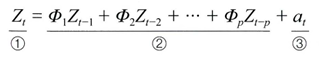

(1)은 시계열 데이터에서 현재 시점을 의미하며, (2)는 과거가 현재에 미치는 영향을 타나내는 모수에 시계열 데이터의 과거 시점을 곱한 것이다.

- MA 모델

: 이동 평균 모델은 트렌드가 변화하는 상황에 적합한 회귀 모델

이동평균 모델에서는 윈도우라는 개념을 사용하는데, 시계열을 따라 윈도우 크기만큼 슬라이딩된다.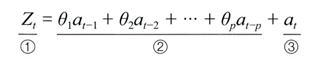

(1)은 시계열 데이터에서 현재 시점을 의미

(2)는 매개변수에 과거 시점의 오차를 곱한 것

(3)은 오차항을 의미

- AR모델과의 차이: 이전 데이터의 **상태**가 아닌 **오차**에서 현재 데이터의 상태를 추론하겠다는 의미이다.

- ARMA 모델

: 자기 회귀 이동 평균 모델은 AR과 MA를 섞은 모델로 연구 기관에서 주로 사용한다.

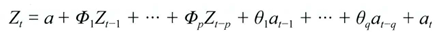

- ARIMA 모델

: 자기 회귀 누적 이동 평균 모델은 자기 회귀와 이동 평균을 둘 다 고려하는 모형

ARMA와 달리 과거 데이터의 선형 관계뿐 아니라 **추세까지** 고려한 모델

statsmodels 라이브러리를 이용하여 ARIMA 모델 구현

ARIMA(p, d, q)함수에서 쓰는 파라미터

1. p: 자기 회귀 차수
2. d: 차분 차수
3. q: 이동 평균 차수

fit() 메서드를 호출하고 모델에 데이터를 적용하여 훈련시킨다.


predict() 메서드를 호출하여 미래의 추세 및 동향에 대해 예측한다.

In [1]:
!pip install statsmodels

In [2]:
!git clone https://github.com/gilbutITbook/080289.git

Cloning into '080289'...
remote: Enumerating objects: 2278, done.
remote: Counting objects: 100% (16/16), done.
remote: Compressing objects: 100% (14/14), done.
remote: Total 2278 (delta 3), reused 2 (delta 2), pack-reused 2262 (from 2)
Receiving objects: 100% (2278/2278), 330.29 MiB | 24.20 MiB/s, done.
Resolving deltas: 100% (13/13), done.
Updating files: 100% (2591/2591), done.


/tmp/ipykernel_640/1480756572.py:10: FutureWarning: The argument 'date_parser' is deprecated and will be removed in a future version. Please use 'date_format' instead, or read your data in as 'object' dtype and then call 'to_datetime'.
  series = read_csv('/content/080289/chap07/data/sales.csv', header=0, parse_dates=[0],
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:                  Sales   No. Observations:                   36
Model:                 ARIMA(5, 1, 0)   Log Likelihood                -199.651
Date:                Sat, 07 Nov 2026   AIC                            411.302
Time:                        10:48:59   BIC                            420.634
Sample:                    01-01-1991   HQIC                           414.523
                         - 12-01-1993                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.8788      0.227     -3.876      0.000      -1.323      -0.434
ar.L2         -0.2787      0.232     -1.203      0.229      -0.733       0.176
ar.L3         -0.0076      0.270     -0.028      0.9

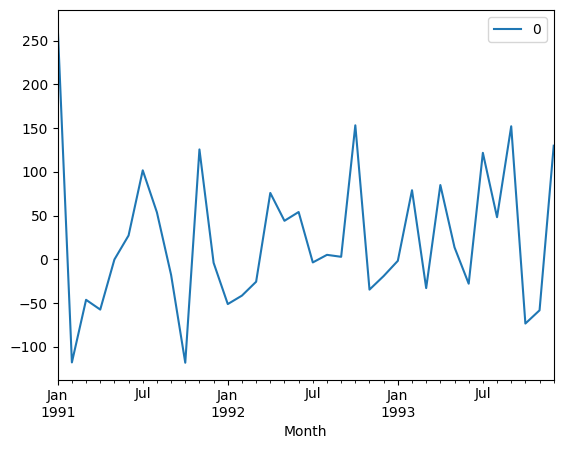

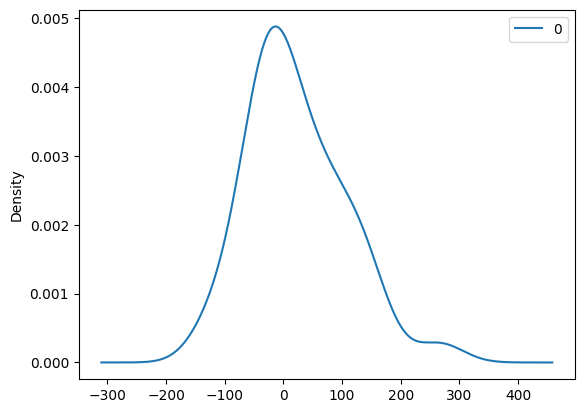

                0
count   36.000000
mean    22.459086
std     82.505331
min   -118.213281
25%    -33.308343
50%      1.361178
75%     76.704967
max    266.000000


In [3]:
from pandas import read_csv
from datetime import datetime
from pandas import DataFrame
from statsmodels.tsa.arima.model import ARIMA
from matplotlib import pyplot

def parser(x):
  return datetime.strptime('199'+x, '%Y-%m')  #strptime()은 날짜와 시간 정보를 문자열로 바꿔주는 메서드

series = read_csv('/content/080289/chap07/data/sales.csv', header=0, parse_dates=[0],
                  index_col=0, date_parser=parser)

model = ARIMA(series, order=(5,1,0))
model_fit = model.fit()
print(model_fit.summary())

residuals = DataFrame(model_fit.resid)
residuals.plot()
pyplot.show()
residuals.plot(kind='kde')
pyplot.show()
print(residuals.describe())

/tmp/ipykernel_640/1291117167.py:11: FutureWarning: The argument 'date_parser' is deprecated and will be removed in a future version. Please use 'date_format' instead, or read your data in as 'object' dtype and then call 'to_datetime'.
  series = read_csv('/content/080289/chap07/data/sales.csv', header=0, parse_dates=[0],


predicted=352.855343, expected=346.300000
predicted=277.398036, expected=329.700000
predicted=368.753734, expected=445.400000
predicted=331.773635, expected=325.900000
predicted=372.070407, expected=449.300000
predicted=360.020872, expected=411.300000
predicted=454.526230, expected=417.400000
predicted=388.690699, expected=545.500000
predicted=437.632447, expected=477.600000
predicted=516.437624, expected=687.000000
predicted=520.916191, expected=435.300000
predicted=675.594647, expected=587.300000
predicted=505.201016, expected=676.900000
Test MSE: 9118.818


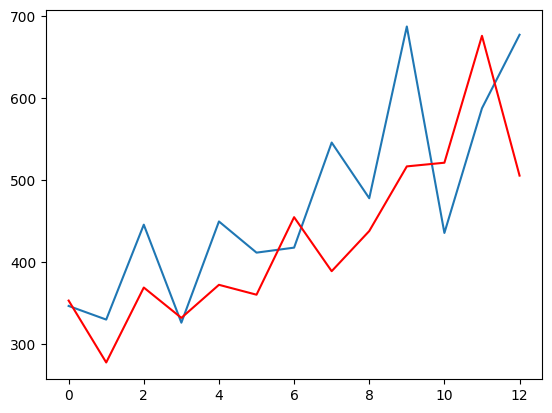

In [4]:
import numpy as np
from pandas import read_csv
from datetime import datetime
from matplotlib import pyplot
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error

def parser(x):
  return datetime.strptime('199'+x, '%Y-%m')

series = read_csv('/content/080289/chap07/data/sales.csv', header=0, parse_dates=[0],
                  index_col=0, date_parser=parser)

X = series.values.flatten()
X = np.nan_to_num(X)
size = int(len(X)*0.66)
train, test = X[0:size], X[size:len(X)]
history = [x for x in train]
predictions = list()
for t in range(len(test)):
  model = ARIMA(history, order=(5,1,0))
  model_fit = model.fit()
  output = model_fit.forecast()
  yhat = output[0]
  predictions.append(yhat)
  obs = test[t]
  history.append(obs)
  print( 'predicted=%f, expected=%f' % (yhat, obs))
error = mean_squared_error(test, predictions)
print('Test MSE: %.3f' % error)
pyplot.plot(test)
pyplot.plot(predictions, color='red')
pyplot.show()

# 7.3 순환 신경망(RNN)

시간적으로 연속성이 있는 데이터를 처리하려고 고안된 인공 신경망

: 이전 은닉층이 현재 은닉층의 입력이 되면서 반복되는 순환구조를 갖는다는 의미

RNN이 기존 네트워크와 다른 점

: 기억을 갖고 있음

-> 새로운 입력이 네트워크로 들어올 때마다 기억이 조금씩 수정, 최종적으로 남겨진 기억은 모든 입력 전체를 요약한 정보
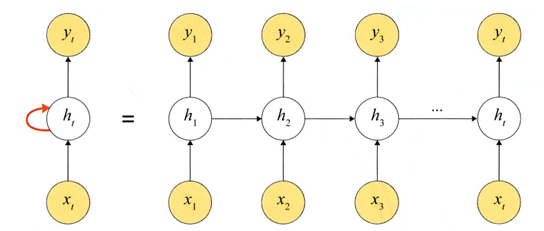

RNN은 입력과 출력에 따라 유형이 다양함
1. 일대일: 순환이 없기 때문에 RNN이라고 말하기 어려움 (순방향 네트워크)
2. 일대다: 입력이 하나이고, 출력이 다수인 구조. 이미지를 입력하여 이미지에 대한 설명을 문장으로 출력하는 이미지 캡션이 대표적 사례
3. 다대일: 입력이 다수, 출력이 하나인 구조. 문장을 입력해서 긍정/부정을 출력하는 감성 분석기에서 사용



```
self.em = nn.Embedding(len(TEXT.vocab.stoi), embedding_dim)
self.rnn = nn.RNNCell(input_dim, hidden_size)
self.fc1 = nn.Linear(hidden_size, 256)
self.fc2 = nn.Linear(256,3)
```

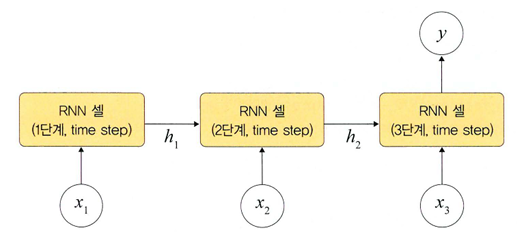

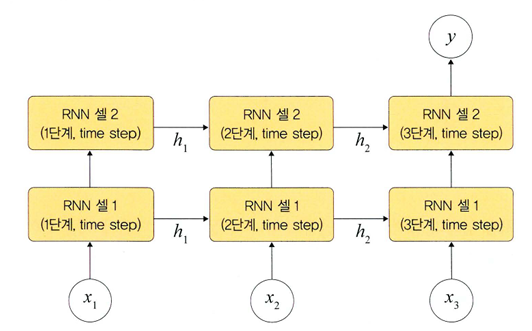

4. 다대다: 입력과 출력이 다수인 구조.

언어를 번역하는 자동 변역기 등이 대표적 사례

파이토치는 테서플로처럼 구현이 간단하지 않다.

파이토치에서는 문장 번역에서 많이 사용되는 시퀀스-투-시퀀스를 이용하는 방식으로 사용된다.


```
Seq25eq(
    (encoder):Encoder(
        (embedding):Embedding(7855, 256)
        (rnn):LSTM(256, 512, num_layers=2, dropout=0.5)
        (dropout):Dropout(p=0.5, inplace=False)
    )
    (decoder): Decoder(
        (embedding): Embedding(5893, 256)
        (rnn):LSTM(256, 512, num_layers=2, dropout=0.5)
        (fc_out): Linear(in_features=512, out_features=5893, bias=True)
        (dropout): Dropout(p=0.5, inplace=False)
    ))
    ```

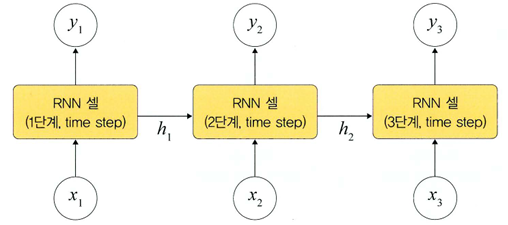

5. 동기화 다대다

4의 유형과 같이 입력과 출력이 다수인 구조

문장에서 다음에 나올 단어를 예측하는 언어 모델, 즉 프레임 수준의 비디오 분류가 대표적 사례

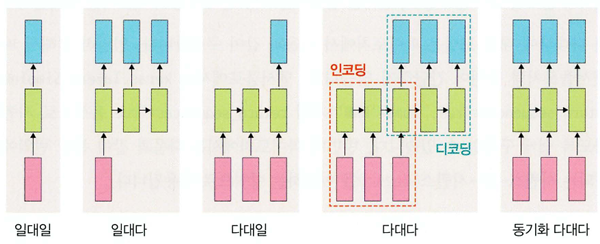

###7.3.1  RNN계층과 셀

RNN은 내장된 계층뿐 아니라 셀 레벨의 API도 제공한다.

RNN계층이 입력된 배치 순서대로 모두 처리하는 것과 다르게 RNN셀은 오직 하나의 단계만 처리한다.

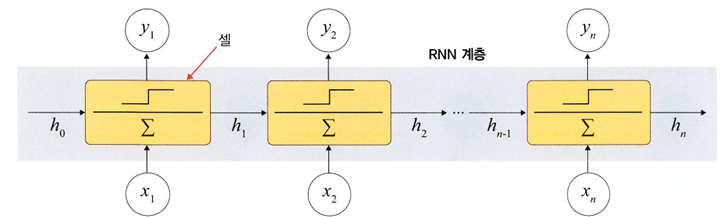


```nn.RNNCell```: SimpleRNN 계층에 대응되는 RNN셀

```nn.GRUCell```: CRU계층에 대응되는 GRU셀

```nn.LSTMCell```:LSTM계층에 대응되는 LSTM셀

파이토치에서는 RNN의 계층과 셀을 분리해서 구현이 가능

대표 활용 분야: 자연어 처리